# 📘 Notebook 03: AlexNet and VGG, When Deep Learning Took Over

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Papers: Krizhevsky, Sutskever and Hinton (2012) · Simonyan and Zisserman (2014)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** AlexNet was trained for about **six days on two GPUs**, and VGG-16 for **two to three weeks on four GPUs**, on 1.2 million photographs. We do **not** retrain them. We build their architectures in code, then load the **official pretrained weights** published with PyTorch (`torchvision`) and use them on new photos: about 240 MB and 530 MB to download, once, and a fraction of a second per image on a laptop processor. The one experiment we do train, ReLU against tanh in Section 4, is a small network on Fashion-MNIST that takes about **four minutes** (two per activation function) on a processor; it reproduces the **idea** of the paper's Figure 1, not its exact setting (a four-layer network on CIFAR-10). The sample photos come with the scikit-image library, so nothing else is downloaded. Five photos are a demonstration, not an evaluation: the papers report accuracy on 50,000 validation images.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain why **ImageNet**, **GPUs** and AlexNet together started the deep learning era in 2012
- Describe AlexNet's architecture and its new ingredients: **ReLU**, **dropout**, **data augmentation**, **GPU training**
- Measure why **ReLU** trains faster than tanh
- Explain VGG's single design rule: **only 3 × 3 convolutions, stacked deep**, and why two 3 × 3 layers beat one 5 × 5
- Load **pretrained** networks, prepare an image the way they expect, and read their **top-5** predictions
- Compare the **size and speed** of AlexNet, VGG-16 and LeNet-5

> **Prerequisites:** [Notebook 02: LeNet-5](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/02_lenet5.ipynb).
>
> 🔭 **Why this notebook matters:** in September 2012, AlexNet won the ImageNet competition with a top-5 error of **15.3%**; the second-best entry, built on hand-designed features, had **26.2%**. Within two years almost every team used deep convolutional networks. The architecture was LeNet's idea made much bigger; what had changed was the **data** (ImageNet) and the **hardware** (GPUs). Using a pretrained network, as we do here, is also how most real image applications start today.

## 1. The papers

> 📄 A. Krizhevsky, I. Sutskever and G. E. Hinton, [*ImageNet Classification with Deep Convolutional Neural Networks*](https://papers.nips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html), NeurIPS 2012.
>
> 📄 K. Simonyan and A. Zisserman, [*Very Deep Convolutional Networks for Large-Scale Image Recognition*](https://arxiv.org/abs/1409.1556), ICLR 2015 (arXiv 2014).
>
> 📄 The data: O. Russakovsky et al., [*ImageNet Large Scale Visual Recognition Challenge*](https://arxiv.org/abs/1409.0575), IJCV 2015.

### Intuition first
LeNet read 28 × 28 digits. ImageNet asks a network to name the object in a **224 × 224 colour photo**, among **1,000 categories**, from dogs of 120 breeds to volcanoes and espresso cups. AlexNet kept LeNet's recipe (convolution, non-linearity, pooling, then fully connected layers) and changed four things:

1. **Bigger:** 5 convolutional layers with up to 384 filters, 3 fully connected layers of 4,096 units, about **60 million** weights against LeNet's 60 thousand.
2. **ReLU** instead of tanh: the function max(0, x), which does not flatten out for large inputs, so gradients do not vanish and training is much faster.
3. **Against overfitting:** **dropout** (randomly switching off half of the fully connected units during training) and **data augmentation** (random crops and flips of every training image).
4. **GPUs:** the network was split across two graphics cards, which made training on 1.2 million images possible in days instead of months.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import alexnet, AlexNet_Weights, vgg16, VGG16_Weights
from skimage import data as skdata

torch.manual_seed(0)
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
count = lambda m: sum(p.numel() for p in m.parameters())
print("PyTorch", torch.__version__, " torchvision", torchvision.__version__)

PyTorch 2.2.2+cpu  torchvision 0.17.2+cpu


## 2. AlexNet in code

In [2]:
class AlexNetFromPaper(nn.Module):
    """AlexNet as in the paper (single-GPU version used by torchvision)."""

    def __init__(self, classes=1000):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=11, stride=4, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(3, 2),
            nn.Conv2d(64, 192, kernel_size=5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(3, 2),
            nn.Conv2d(192, 384, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(3, 2),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.5), nn.Linear(256 * 6 * 6, 4096), nn.ReLU(inplace=True),
            nn.Dropout(0.5), nn.Linear(4096, 4096), nn.ReLU(inplace=True),
            nn.Linear(4096, classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(F.adaptive_avg_pool2d(x, (6, 6)), 1)
        return self.classifier(x)

ours = AlexNetFromPaper()
x = torch.zeros(1, 3, 224, 224)
for layer in ours.features:
    x = layer(x)
    if isinstance(layer, (nn.Conv2d, nn.MaxPool2d)):
        print(f"{layer.__class__.__name__:10s} -> {tuple(x.shape)}")
conv = sum(p.numel() for p in ours.features.parameters())
print(f"\nweights: {count(ours):,} in total, of which {conv:,} in the convolutional layers")

Conv2d     -> (1, 64, 55, 55)
MaxPool2d  -> (1, 64, 27, 27)
Conv2d     -> (1, 192, 27, 27)
MaxPool2d  -> (1, 192, 13, 13)
Conv2d     -> (1, 384, 13, 13)
Conv2d     -> (1, 256, 13, 13)
Conv2d     -> (1, 256, 13, 13)
MaxPool2d  -> (1, 256, 6, 6)

weights: 61,100,840 in total, of which 2,469,696 in the convolutional layers


**What we see.** The image shrinks fast: the first layer, with 11 × 11 filters and a stride of 4, turns 224 × 224 into 55 × 55, and after the last pooling 256 maps of 6 × 6 remain. The striking number is the split of the **61.1 million** weights: only **2.5 million (4%)** are in the five convolutional layers; the other 96% are in the three fully connected layers at the end. The part that "sees" is small; the part that decides is huge.

## 3. Using the pretrained AlexNet

### How to feed a pretrained network
A pretrained network expects images prepared **exactly** as during its training: resized, cropped to 224 × 224, and each colour channel normalised with the mean and standard deviation of ImageNet. The weights object carries these steps, so we use `weights.transforms()` instead of guessing.

our architecture and torchvision's have the same number of weights: True
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


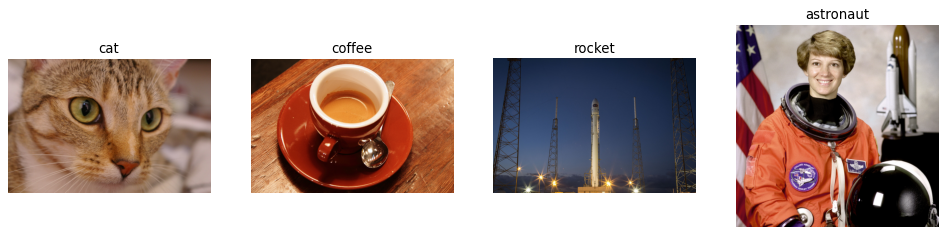

cat        [('Egyptian cat', 0.788), ('tiger cat', 0.135), ('tabby', 0.072), ('lynx', 0.005), ('Persian cat', 0.0)]
coffee     [('espresso', 0.972), ('consomme', 0.017), ('cup', 0.004), ('soup bowl', 0.002), ('bagel', 0.001)]
rocket     [('mosque', 0.623), ('drilling platform', 0.174), ('obelisk', 0.073), ('pole', 0.043), ('palace', 0.018)]
astronaut  [('dumbbell', 0.267), ('puck', 0.062), ('neck brace', 0.053), ('drum', 0.04), ("potter's wheel", 0.03)]


In [3]:
weights_a = AlexNet_Weights.IMAGENET1K_V1
net_a = alexnet(weights=weights_a, progress=False).eval()
prepare = weights_a.transforms()
categories = weights_a.meta["categories"]
print("our architecture and torchvision's have the same number of weights:", count(net_a) == count(ours))
print(prepare)

photos = {"cat": skdata.chelsea(), "coffee": skdata.coffee(), "rocket": skdata.rocket(), "astronaut": skdata.astronaut()}

def top5(net, image, prepare):
    x = prepare(torch.tensor(image).permute(2, 0, 1))[None]
    with torch.no_grad():
        p = net(x).softmax(1)[0]
    values, idx = p.topk(5)
    return [(categories[i], round(v.item(), 3)) for v, i in zip(values, idx)]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (name, image) in zip(axes, photos.items()):
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
plt.show()
for name, image in photos.items():
    print(f"{name:10s}", top5(net_a, image, prepare))

**What we see.** Our hand-written architecture has exactly as many weights as torchvision's, so the pretrained weights fit it. The preparation is printed too: resize to 256, crop the central 224 × 224, normalise with ImageNet's channel means and deviations.
- **Cat:** "Egyptian cat" with **79%**, then tiger cat and tabby: all three are cat categories of ImageNet, and the network is right.
- **Coffee:** "espresso" with **97%**.
- **Rocket:** "mosque" with **62%**. Wrong, but understandable: a tall pointed white shape against the sky, which the network has learned to associate with minarets.
- **Astronaut:** "dumbbell" with only **27%**, and a spread of unrelated guesses. ImageNet has **no** category for people or astronauts, so the network is forced to choose among objects it knows, and its low confidence says so.

A classifier can only answer with the categories it was trained on; low confidence is often the only warning that a photo is outside its world.

## 4. Why ReLU? Reproducing the idea of Figure 1

The paper's Figure 1 shows a small network reaching 25% training error **six times faster** with ReLU than with tanh. We repeat the idea on Fashion-MNIST: the same small convolutional network, once with ReLU and once with tanh, trained identically for 3 epochs.

ReLU: final training error 0.085, 109 s


tanh: final training error 0.085, 93 s


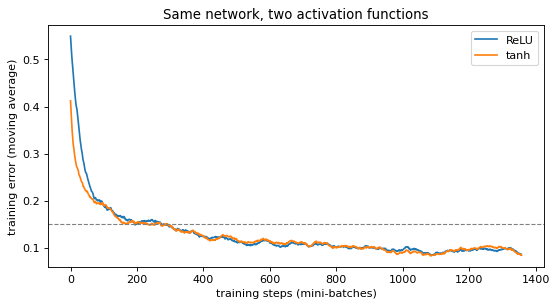

ReLU: steps to reach 15% training error: 194
tanh: steps to reach 15% training error: 233


In [4]:
import gzip
import urllib.request

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)
Xf = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 1, 28, 28), dtype=torch.float32) / 255
yf = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)

def small_cnn(act):
    return nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), act(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 64, 3, padding=1), act(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(64 * 7 * 7, 128), act(), nn.Linear(128, 10))

def train_curve(act, epochs=3, batch=128):
    torch.manual_seed(0)
    model = small_cnn(act)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    errors, start = [], time.time()
    for _ in range(epochs):
        order = torch.randperm(len(Xf))
        for i in range(0, len(Xf), batch):
            idx = order[i:i + batch]
            out = model(Xf[idx])
            loss = F.cross_entropy(out, yf[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            errors.append((out.argmax(1) != yf[idx]).float().mean().item())
    return np.convolve(errors, np.ones(50) / 50, mode="valid"), time.time() - start

curves = {}
for name, act in [("ReLU", nn.ReLU), ("tanh", nn.Tanh)]:
    curves[name], seconds = train_curve(act)
    print(f"{name}: final training error {curves[name][-1]:.3f}, {seconds:.0f} s")

plt.figure(figsize=(8, 4))
for name, c in curves.items():
    plt.plot(c, label=name)
plt.axhline(0.15, color="grey", linestyle="--", linewidth=1)
plt.xlabel("training steps (mini-batches)")
plt.ylabel("training error (moving average)")
plt.legend()
plt.title("Same network, two activation functions")
plt.show()
for name, c in curves.items():
    print(f"{name}: steps to reach 15% training error:", int(np.argmax(c < 0.15)) if (c < 0.15).any() else "not reached")

**What we see.** An honest result. With this small two-layer network and modern training (SGD with momentum), **ReLU** gets below 15% training error in **194** steps against **233** for tanh, about **20% faster**, and both end at the same 8.5% error after 3 epochs. That is a real advantage, but far from the six-fold gap of the paper's Figure 1.

The difference is in the setting. The paper's gap came from deeper networks trained with plain gradient descent, where tanh units **saturate** (they flatten out at -1 and 1, so their gradient almost vanishes) and learning crawls. Modern tricks (momentum, careful initialisation, and later batch normalisation) shrink the gap, and in a quick test with a six-layer network, plain SGD and PyTorch's default initialisation, it was the ReLU network that failed to train at all, until a better initialisation was used (He et al., 2015). Activation functions, initialisation and optimiser work **together**; a claim about one of them holds only in a setting like the one where it was measured. ReLU's lasting victory is in **very deep** networks, as Notebook 04 shows.

## 5. VGG: one rule, applied deeply

### Intuition first
AlexNet mixed 11 × 11, 5 × 5 and 3 × 3 filters, chosen by trial and error. Two years later, Simonyan and Zisserman asked a simpler question: what if **every** filter is 3 × 3, and we just go **deeper**? Their VGG-16 has 13 convolutional layers, all 3 × 3, in five blocks separated by pooling.

Why small filters? Two 3 × 3 layers in a row "see" a 5 × 5 patch of the input, the same as one 5 × 5 filter, but they need **fewer weights** and add an **extra non-linearity** in between, so they can represent more complex patterns.

In [5]:
C = 256
print(f"one 5x5 layer, {C} -> {C} channels:     {5 * 5 * C * C:,} weights")
print(f"two 3x3 layers, {C} -> {C} channels:    {2 * 3 * 3 * C * C:,} weights")
print(f"one 7x7 layer:                          {7 * 7 * C * C:,} weights")
print(f"three 3x3 layers (same 7x7 view):       {3 * 3 * 3 * C * C:,} weights")

one 5x5 layer, 256 -> 256 channels:     1,638,400 weights
two 3x3 layers, 256 -> 256 channels:    1,179,648 weights
one 7x7 layer:                          3,211,264 weights
three 3x3 layers (same 7x7 view):       1,769,472 weights


**What we see.** Two 3 × 3 layers cover the same 5 × 5 view as one 5 × 5 layer with **28% fewer** weights (1.18 million against 1.64 million for 256 channels), and three 3 × 3 layers cover a 7 × 7 view with **45% fewer** (1.77 against 3.21 million), while adding two extra non-linearities. Small filters stacked deep are cheaper and more expressive.

In [6]:
weights_v = VGG16_Weights.IMAGENET1K_V1
net_v = vgg16(weights=weights_v, progress=False).eval()
convs = [m for m in net_v.features if isinstance(m, nn.Conv2d)]
print("VGG-16 convolutional layers:", len(convs), " all 3x3:", all(m.kernel_size == (3, 3) for m in convs))
for name, image in photos.items():
    print(f"{name:10s}", top5(net_v, image, weights_v.transforms()))

VGG-16 convolutional layers: 13  all 3x3: True


cat        [('Egyptian cat', 0.578), ('tabby', 0.215), ('tiger cat', 0.202), ('lynx', 0.003), ('plastic bag', 0.0)]


coffee     [('espresso', 0.982), ('consomme', 0.009), ('cup', 0.007), ('coffee mug', 0.001), ('soup bowl', 0.001)]


rocket     [('missile', 0.437), ('projectile', 0.199), ('drilling platform', 0.106), ('pole', 0.072), ('water tower', 0.041)]


astronaut  [('stethoscope', 0.233), ('drumstick', 0.081), ('puck', 0.081), ('drum', 0.072), ('vacuum', 0.044)]


**What we see.** All 13 convolutional layers of VGG-16 are 3 × 3. Its predictions are close to AlexNet's on the cat and the coffee (espresso **98%**), with two telling differences:
- **Rocket:** VGG says **"missile"** (44%), then projectile: a far better answer than AlexNet's mosque.
- **Astronaut:** still a forced guess (stethoscope, 23%), because no network can name a category it was never taught.

The cat's probability is lower than AlexNet's (58% against 79%), but spread across three cat breeds: a deeper network is not always more confident, but it confuses **similar** things rather than unrelated ones.

## 6. The price of size

In [7]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 6, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(6, 16, 5), nn.ReLU(),
                                 nn.MaxPool2d(2), nn.Flatten(), nn.Linear(400, 120), nn.ReLU(), nn.Linear(120, 84), nn.ReLU(), nn.Linear(84, 10))
    def forward(self, x):
        return self.net(x)

def seconds_per_image(net, shape, repeats=5):
    x = torch.zeros(shape)
    with torch.no_grad():
        net(x)
        start = time.time()
        for _ in range(repeats):
            net(x)
    return (time.time() - start) / repeats

rows = [("LeNet-5 (1998)", LeNet5().eval(), (1, 1, 28, 28)),
        ("AlexNet (2012)", net_a, (1, 3, 224, 224)),
        ("VGG-16 (2014)", net_v, (1, 3, 224, 224))]
print(f"{'model':16s}{'weights':>14s}{'size (MB)':>12s}{'ms per image':>15s}")
for name, net, shape in rows:
    print(f"{name:16s}{count(net):>14,}{count(net) * 4 / 1e6:>12.1f}{1000 * seconds_per_image(net, shape):>15.1f}")

model                  weights   size (MB)   ms per image
LeNet-5 (1998)          61,706         0.2            0.6
AlexNet (2012)      61,100,840       244.4           22.6


VGG-16 (2014)      138,357,544       553.4          219.4


**What we see.** Fourteen years of progress in one table:
- **LeNet-5:** 62 thousand weights, under 1 MB.
- **AlexNet:** 61 million weights, about **244 MB**, a few tens of milliseconds per image on this processor.
- **VGG-16:** 138 million weights, about **553 MB**, roughly **ten times slower** than AlexNet per image.

(The milliseconds vary between runs and machines; the ratios are what matter.) VGG bought its accuracy with size and computation. Most of that cost is in its fully connected layers, which the next generation of networks would remove almost entirely.

## ⚠️ Common pitfalls

- **Feeding a pretrained network unprepared images.** Wrong size, wrong channel order or missing normalisation silently ruins predictions; always use the transforms that come with the weights.
- **Forgetting `model.eval()`.** Dropout is active in training mode, so predictions would change at random from one call to the next.
- **Expecting a pretrained network to know everything.** It knows its 1,000 ImageNet categories and nothing else; anything outside them is forced into the nearest one.
- **Comparing accuracy without counting cost.** VGG-16 has more than twice AlexNet's weights and is much slower; the next notebooks show that more depth can be bought far more cheaply.
- **Reading a small demo as an evaluation.** Five photos show how to use a model; they do not measure it.

## ✏️ Exercises

### Exercise 1 (A flipped cat)
AlexNet was trained with random **horizontal** flips. Flip the cat photo horizontally (`image[:, ::-1]`) and vertically (`image[::-1]`), and compare AlexNet's top prediction and its probability. Which flip hurts more, and why?

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
cat = photos["cat"]
for name, image in [("original", cat), ("horizontal flip", np.ascontiguousarray(cat[:, ::-1])), ("vertical flip", np.ascontiguousarray(cat[::-1]))]:
    print(f"{name:16s}", top5(net_a, image, prepare)[:2])
```

*A horizontal flip changes almost nothing: the network saw mirrored cats throughout training. An upside-down cat is rare in photos and was never added by augmentation, so the network is less sure or wrong. Augmentation teaches a network exactly the variations you show it, and no others.*
</details>

### Exercise 2 (Dropout in action)
Put the pretrained AlexNet in **training** mode (`net_a.train()`) and predict the cat 5 times. Do the probabilities change? Put it back with `net_a.eval()` afterwards.

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
net_a.train()
for _ in range(5):
    print(top5(net_a, photos["cat"], prepare)[0])
net_a.eval()
print("eval mode:", top5(net_a, photos["cat"], prepare)[0])
```

*In training mode dropout switches off a random half of the fully connected units on every call, so the probabilities change each time. This randomness is what fights overfitting during training; at prediction time it must be off.*
</details>

### Exercise 3 (Count the weights yourself)
Compute by hand the number of weights of AlexNet's **first** convolutional layer (3 input channels, 64 filters of 11 × 11, plus one bias per filter) and of its **first fully connected layer** (256 × 6 × 6 inputs, 4,096 outputs, plus biases). Check with PyTorch. Which is larger, and by how much?

In [10]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
first_conv = 3 * 11 * 11 * 64 + 64
first_fc = 256 * 6 * 6 * 4096 + 4096
print(first_conv, sum(p.numel() for p in ours.features[0].parameters()))
print(first_fc, sum(p.numel() for p in ours.classifier[1].parameters()))
print("ratio:", round(first_fc / first_conv))
```

*The first fully connected layer alone has about 38 million weights, more than 1,600 times the first convolution. Shared filters are cheap; connecting everything to everything is expensive. Later architectures (ResNet, Notebook 04) remove almost all of these fully connected weights.*
</details>

## 🔑 Key takeaways

- AlexNet (2012) was **LeNet scaled up**, made trainable by **GPUs**, **ImageNet**, **ReLU**, **dropout** and **data augmentation**.
- **ReLU** keeps gradients alive and trains much faster than tanh.
- VGG (2014) showed that **depth with small 3 × 3 filters** beats hand-chosen large filters, with fewer weights per layer.
- Most of AlexNet's and VGG's weights sit in the **fully connected layers**; they are large and slow.
- **Pretrained networks** let anyone use years of GPU training in a few lines, as long as images are prepared exactly as in training.

---
**Next:** *Notebook 04: ResNet*, where going even deeper first made networks **worse**, and a simple shortcut connection fixed it.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*